<a href="https://colab.research.google.com/github/kpate18/ECGR-4105/blob/main/homework%206/Problem_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

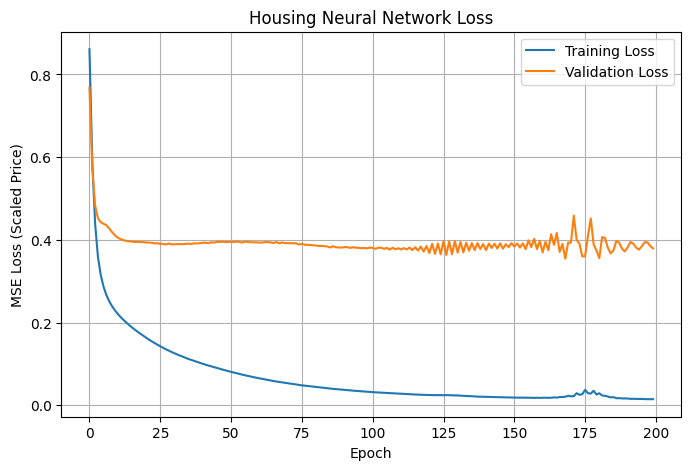


Housing Model Comparison:
                            MSE          RMSE  R2 Score
Neural Network     2.287762e+12  1.512535e+06    0.5474
Linear Regression  1.754319e+12  1.324507e+06    0.6529
SVR                2.535562e+12  1.592345e+06    0.4984

Best Model (Lowest RMSE):
Linear Regression


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv("Housing.csv")

# Remove rows with missing values
df = df.dropna()

# 2. Separate input features and target
X = df.drop(columns=["price"])
y = df["price"]

# Convert categorical columns into numeric values
X = pd.get_dummies(X, drop_first=True, dtype=int)

# 3. Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Standardize input features
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

# Standardize target for neural network and SVR
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# 5. Build neural network
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

# 6. Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# 7. Train model
history = model.fit(
    X_train,
    y_train_scaled,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    verbose=0
)

# 8. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Scaled Price)")
plt.title("Housing Neural Network Loss")
plt.legend()
plt.grid(True)
plt.show()

# 9. Predict using neural network
nn_scaled_pred = model.predict(X_test, verbose=0)
nn_pred = scaler_y.inverse_transform(
    nn_scaled_pred
).ravel()

# 10. Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

# 11. Train SVR
svr_model = SVR(kernel="rbf", C=100, epsilon=0.1)
svr_model.fit(X_train, y_train_scaled)

svr_scaled_pred = svr_model.predict(X_test)
svr_pred = scaler_y.inverse_transform(
    svr_scaled_pred.reshape(-1, 1)
).ravel()

# 12. Calculate evaluation metrics
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return [mse, rmse, r2]

# 13. Compare all three models
results = pd.DataFrame(
    [
        regression_metrics(y_test, nn_pred),
        regression_metrics(y_test, linear_pred),
        regression_metrics(y_test, svr_pred)
    ],
    columns=["MSE", "RMSE", "R2 Score"],
    index=["Neural Network", "Linear Regression", "SVR"]
)

print("\nHousing Model Comparison:")
print(results.round(4).to_string())

print("\nBest Model (Lowest RMSE):")
print(results["RMSE"].idxmin())
